# Байесовские сети
### Датасет: [Deutsche Bank Dataset](https://www.kaggle.com/datasets/saswatsethda/deutsche-bank-dataset)

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np


%matplotlib inline
sns.set_theme(style="darkgrid")

df = pd.read_csv("Churn_Modelling.csv", sep=",")

print(df.shape)
print(df.head())

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

(10000, 14)
   RowNumber  CustomerId   Surname  CreditScore Geography  Gender  Age  \
0          1    15634602  Hargrave          619    France  Female   42   
1          2    15647311      Hill          608     Spain  Female   41   
2          3    15619304      Onio          502    France  Female   42   
3          4    15701354      Boni          699    France  Female   39   
4          5    15737888  Mitchell          850     Spain  Female   43   

   Tenure    Balance  NumOfProducts  HasCrCard  IsActiveMember  \
0       2       0.00              1          1               1   
1       1   83807.86              1          0               1   
2       8  159660.80              3          1               0   
3       1       0.00              2          0               0   
4       2  125510.82              1          1               1   

   EstimatedSalary  Exited  
0        101348.88       1  
1        112542.58       0  
2        113931.57       1  
3         93826.63       0  
4

## 1. Описание данных и предметной области

**Объект** — отдельный клиент банка и его характеристики на момент наблюдения, включая факт ухода из банка. Всего в выборке 10 000 наблюдений и 14 признаков.

**Признаки:**
- `RowNumber`, `CustomerId`, `Surname` — технические идентификаторы клиента (не несут статистической информации о зависимостях).
- `Geography` — страна обслуживания (`France`, `Germany`, `Spain`).
- `Gender` — пол клиента.
- `Age` — возраст клиента (лет).
- `CreditScore` — кредитный рейтинг.
- `Tenure` — срок обслуживания в банке (лет).
- `Balance` — текущий баланс счёта.
- `NumOfProducts` — количество используемых банковских продуктов.
- `HasCrCard` — наличие кредитной карты (0/1).
- `IsActiveMember` — статус активного клиента (0/1).
- `EstimatedSalary` — оценочный годовой доход.
- `Exited` — факт ухода клиента из банка (0 — остался, 1 — ушёл).

**Предварительные гипотезы о зависимостях:**
- Страна обслуживания может влиять как на характер счетов (`Balance`), так и на общий уровень оттока (`Exited`).
- Возраст клиента (`Age`) связан с активностью (`IsActiveMember`) и вероятностью ухода (`Exited`).
- Наличие средств на счёте (`Balance`) связано с набором используемых продуктов (`NumOfProducts`).
- Уход клиента (`Exited`) зависит от совокупности факторов: страны, возраста, числа продуктов и активности.

In [2]:
summary = pd.DataFrame({
    "dtype": df.dtypes,
    "missing": df.isna().sum(),
    "nunique": df.nunique(),
})
print(f"Полных дубликатов строк: {df.duplicated().sum()}")
print(f"Дубликатов CustomerId:   {df['CustomerId'].duplicated().sum()}")
display(summary)

num_cols = ["CreditScore", "Age", "Tenure", "Balance", "EstimatedSalary"] #описательные статистики числовых признаков
display(df[num_cols].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(2))

zero_bal_share = (df["Balance"] == 0).mean()
print(f"Доля клиентов с Balance == 0: {zero_bal_share:.2%}")
print(f"Медиана Balance среди Balance > 0: {df.loc[df['Balance'] > 0, 'Balance'].median():,.2f}")

cat_cols = ["Geography", "Gender", "NumOfProducts", "HasCrCard", "IsActiveMember", "Exited"] #частоты категориальных и дискретных признаков (ищем редкие категории)
for col in cat_cols:
    vc = df[col].value_counts(dropna=False).sort_index()
    pct = (vc / len(df) * 100).round(2)
    print(f"\n {col}")
    display(pd.DataFrame({"count": vc, "share_%": pct}))

Полных дубликатов строк: 0
Дубликатов CustomerId:   0


,dtype,missing,nunique
RowNumber,int64,0,10000
CustomerId,int64,0,10000
Surname,object,0,2932
CreditScore,int64,0,460
Geography,object,0,3
Gender,object,0,2
Age,int64,0,70
Tenure,int64,0,11
Balance,float64,0,6382
NumOfProducts,int64,0,4


,CreditScore,Age,Tenure,Balance,EstimatedSalary
count,10000.00,10000.00,10000.00,10000.00,10000.00
mean,650.53,38.92,5.01,76485.89,100090.24
std,96.65,10.49,2.89,62397.41,57510.49
min,350.00,18.00,0.00,0.00,11.58
10%,521.00,27.00,1.00,0.00,20273.58
25%,584.00,32.00,3.00,0.00,51002.11
50%,652.00,37.00,5.00,97198.54,100193.92
75%,718.00,44.00,7.00,127644.24,149388.25
90%,778.00,53.00,9.00,149244.79,179674.70
max,850.00,92.00,10.00,250898.09,199992.48


Доля клиентов с Balance == 0: 36.17%
Медиана Balance среди Balance > 0: 119,839.69

 Geography


,count,share_%
Geography,,
France,5014,50.14
Germany,2509,25.09
Spain,2477,24.77



 Gender


... (5 outputs left out)


 IsActiveMember


,count,share_%
IsActiveMember,,
0,4849,48.49
1,5151,51.51



 Exited


,count,share_%
Exited,,
0,7963,79.63
1,2037,20.37


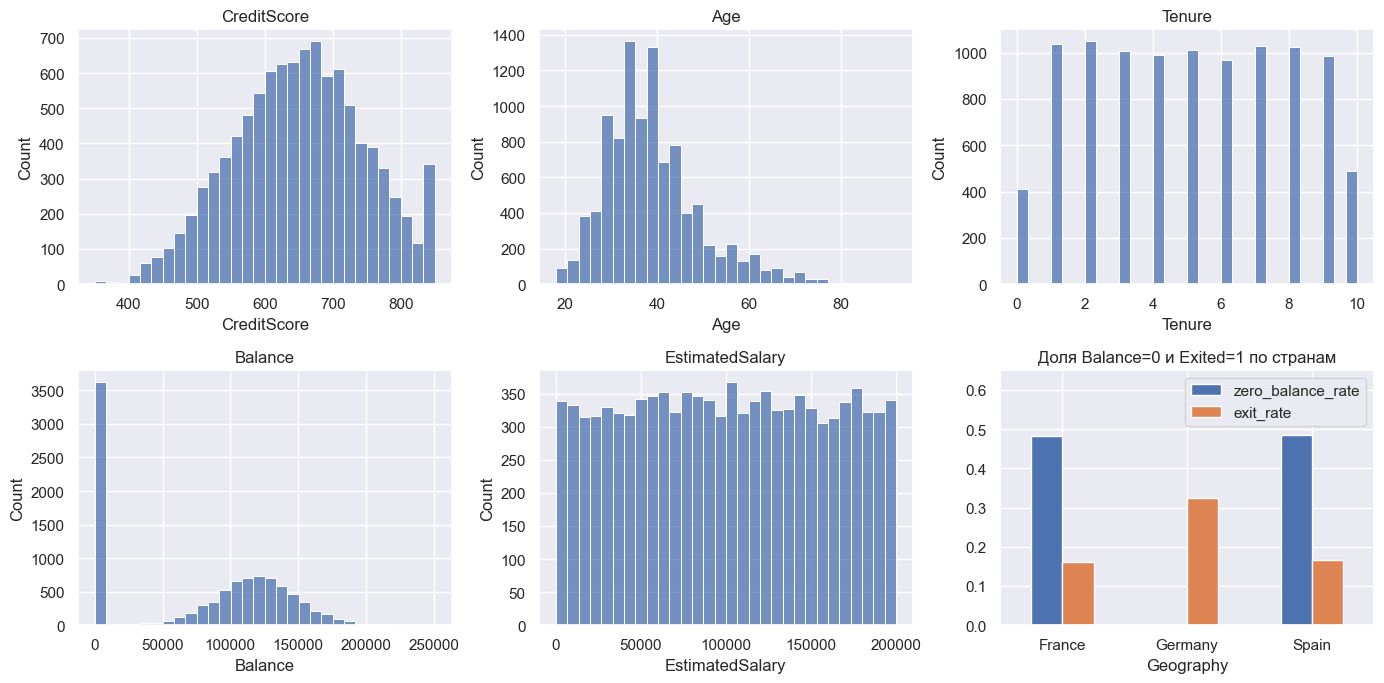

Доля Exited=1 по признакам:


,size,exit_rate
Geography,,
France,5014,0.1615
Germany,2509,0.3244
Spain,2477,0.1667


,size,exit_rate
Gender,,
Female,4543,0.2507
Male,5457,0.1646


,size,exit_rate
NumOfProducts,,
1,5084,0.2771
2,4590,0.0758
3,266,0.8271
4,60,1.0000


,size,exit_rate
HasCrCard,,
0,2945,0.2081
1,7055,0.2018


,size,exit_rate
IsActiveMember,,
0,4849,0.2685
1,5151,0.1427



Сравнение средних и медиан числовых признаков при Exited=0 vs Exited=1:


CreditScore           Age        Tenure          Balance             \
              mean median   mean median   mean median      mean     median   
Exited                                                                       
0           651.85  653.0  37.41   36.0   5.03    5.0  72745.30   92072.68   
1           645.35  646.0  44.84   45.0   4.93    5.0  91108.54  109349.29   

       EstimatedSalary             
                  mean     median  
Exited                             
0             99738.39   99645.04  
1            101465.68  102460.84

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(df[col], bins=30, kde=False, ax=ax)
    ax.set_title(col)

geo_stats = df.groupby("Geography").agg( #доля нулевого баланса и оттока по странам

    n=("Exited", "size"),
    zero_balance_rate=("Balance", lambda s: (s == 0).mean()),
    exit_rate=("Exited", "mean"),
)
geo_stats[["zero_balance_rate", "exit_rate"]].plot(kind="bar", ax=axes.flat[-1], rot=0)
axes.flat[-1].set_title("Доля Balance=0 и Exited=1 по странам")
axes.flat[-1].set_ylim(0, 0.65)
plt.tight_layout()
plt.show()

# Срез: как Exited связан с дискретными и квантильно-разбитыми числовыми признаками
print("Доля Exited=1 по признакам:")
for col in ["Geography", "Gender", "NumOfProducts", "HasCrCard", "IsActiveMember"]:
    display(df.groupby(col)["Exited"].agg(["size", "mean"]).rename(columns={"mean": "exit_rate"}).round(4))

print("\nСравнение средних и медиан числовых признаков при Exited=0 vs Exited=1:")
display(df.groupby("Exited")[num_cols].agg(["mean", "median"]).round(2))

## 2. Подготовка данных и дискретизация

**Итоги первичного анализа и отбор переменных:**
- Пропущенных значений и дубликатов в датасете нет.
- Технические идентификаторы (`RowNumber`, `CustomerId`, `Surname`) исключаются, так как не описывают вероятностные зависимости между свойствами клиента.
- Признаки `CreditScore`, `Tenure`, `EstimatedSalary` и `HasCrCard` не включаются в модель, поскольку их распределения практически не различаются для оставшихся и ушедших клиентов. Признак `Gender` (хотя и даёт различие в оттоке: 25,1% против 16,5%) также оставляем за рамками базового графа, чтобы не удваивать размер таблицы условных вероятностей целевого узла `Exited` и сохранить достаточную наполненность комбинаций родителей.
- В модель отбираем 6 содержательных переменных: `Geo`, `AgeGrp`, `BalGrp`, `ProdGrp`, `Active`, `Exited`.

**Способ и обоснование дискретизации:**
- `Geo` (`Geography`): оставляем исходные 3 категории (`France`, `Germany`, `Spain`) - все хорошо наполнены (от 2 477 до 5 014 наблюдений).
- `AgeGrp` (`Age`, диапазон 18–92, медиана 37): разбиваем на 3 содержательные возрастные группы - `Young` (18–34), `Mid` (35–49) и `Old` (50+). У ушедших клиентов медианный возраст заметно выше (45 против 36), а 3 категории вместо 5+ удерживают компактный размер CPT.
- `BalGrp` (`Balance`): 36,17% клиентов имеют строго нулевой баланс, а среди ненулевых медиана равна 119 839,69. Поэтому стандартное квантильное разбиение некорректно - выделяем отдельный класс `Zero` ($= 0$), а остальные делим по круглому порогу `120 000` (близкому к медиане ненулевых балансов) на `Mid` и `High`.
- `ProdGrp` (`NumOfProducts`): категории `3` (266 строк, 2,66%) и `4` (60 строк, 0,60%) слишком редки для условных таблиц с несколькими родителями и обе имеют экстремально высокий отток (82,7% и 100%). Объединяем их в одну категорию `3+`, получая 3 состояния: `1`, `2`, `3+`.
- `Active` (`IsActiveMember`) и `Exited`: готовые бинарные переменные (`0` и `1`).

In [4]:
from sklearn.model_selection import train_test_split


NODES = ("Geo", "AgeGrp", "BalGrp", "ProdGrp", "Active", "Exited")
STATE_NAMES = {
    "Geo": ["France", "Germany", "Spain"],
    "AgeGrp": ["Young", "Mid", "Old"],
    "BalGrp": ["Zero", "Mid", "High"],
    "ProdGrp": ["1", "2", "3+"],
    "Active": [0, 1],
    "Exited": [0, 1],
}

bn_df = pd.DataFrame({
    "Geo": df["Geography"].astype(str),
    "AgeGrp": pd.cut(df["Age"], bins=[0, 34, 49, 120], labels=["Young", "Mid", "Old"],).astype(str),
    "BalGrp": np.select([df["Balance"] == 0, df["Balance"] <= 120_000], ["Zero", "Mid"], default="High",),
    "ProdGrp": np.where(df["NumOfProducts"] >= 3, "3+", df["NumOfProducts"].astype(str)),
    "Active": df["IsActiveMember"].astype(int),
    "Exited": df["Exited"].astype(int),
})


train_df, test_df = train_test_split(
    bn_df, 
    test_size=0.2, 
    random_state=RANDOM_STATE, 
    stratify=bn_df["Exited"]
)
print(f"Train: {len(train_df):,} объектов | Test: {len(test_df):,} объектов")

# Распределения новых дискретных признаков на всей выборке
print("\nЧастоты дискретизированных переменных:")
for col in ["AgeGrp", "BalGrp", "ProdGrp"]:
    vc = bn_df[col].value_counts().reindex(STATE_NAMES[col])
    pct = (vc / len(bn_df) * 100).round(2)
    display(pd.DataFrame({"count": vc, "share_%": pct, "exit_rate": bn_df.groupby(col)["Exited"].mean().reindex(STATE_NAMES[col]).round(4)}))

Train: 8,000 объектов | Test: 2,000 объектов

Частоты дискретизированных переменных:


,count,share_%,exit_rate
AgeGrp,,,
Young,3679,36.79,0.0788
Mid,4926,49.26,0.2259
Old,1395,13.95,0.4545


,count,share_%,exit_rate
BalGrp,,,
Zero,3617,36.17,0.1382
Mid,3202,32.02,0.2411
High,3181,31.81,0.2405


,count,share_%,exit_rate
ProdGrp,,,
1,5084,50.84,0.2771
2,4590,45.90,0.0758
3+,326,3.26,0.8589


In [5]:
print("1) Таблица сопряжённости Geo x BalGrp (train):")
display(pd.crosstab(train_df["Geo"], train_df["BalGrp"]).reindex(
    index=STATE_NAMES["Geo"], columns=STATE_NAMES["BalGrp"], fill_value=0
))

print("\n2) Таблица сопряжённости BalGrp x ProdGrp (train):")
display(pd.crosstab(train_df["BalGrp"], train_df["ProdGrp"]).reindex(
    index=STATE_NAMES["BalGrp"], columns=STATE_NAMES["ProdGrp"], fill_value=0
))

print("\n3) Таблица сопряжённости AgeGrp x Active (train):")
display(pd.crosstab(train_df["AgeGrp"], train_df["Active"], normalize="index").reindex(
    index=STATE_NAMES["AgeGrp"], columns=STATE_NAMES["Active"]
).round(4))


parent_cols = ["Geo", "AgeGrp", "ProdGrp", "Active"]
full_idx = pd.MultiIndex.from_product(
    [STATE_NAMES[c] for c in parent_cols], names=parent_cols
)
exited_support = ( #4 родителя -> 3*3*3*2 = 54 конфигурации
    train_df.groupby(parent_cols, observed=False)["Exited"]
    .agg(n="size", n_exited="sum", exit_rate="mean")
    .reindex(full_idx)
    .fillna({"n": 0, "n_exited": 0})
)
exited_support["n"] = exited_support["n"].astype(int)
exited_support["n_exited"] = exited_support["n_exited"].astype(int)

print(f"\n4) Поддержка комбинаций родителей для Exited (всего {len(exited_support)} конфигураций):")
print(f"   Пустых (n = 0):           {(exited_support['n'] == 0).sum()}")
print(f"   Редких (1 <= n < 10):     {((exited_support['n'] > 0) & (exited_support['n'] < 10)).sum()}")
print(f"   Достаточных (n >= 10):    {(exited_support['n'] >= 10).sum()}")
print("\nСамые малонаполненные комбинации родителей Exited:")
display(exited_support.sort_values("n").head(12))

1) Таблица сопряжённости Geo x BalGrp (train):


BalGrp,Zero,Mid,High
Geo,,,
France,1930,1030,1033
Germany,0,1013,992
Spain,961,524,517



2) Таблица сопряжённости BalGrp x ProdGrp (train):


ProdGrp,1,2,3+
BalGrp,,,
Zero,723,2077,91
Mid,1670,814,83
High,1678,781,83



3) Таблица сопряжённости AgeGrp x Active (train):


Active,0,1
AgeGrp,,
Young,0.4896,0.5104
Mid,0.5188,0.4812
Old,0.3556,0.6444



4) Поддержка комбинаций родителей для Exited (всего 54 конфигураций):
   Пустых (n = 0):           0
   Редких (1 <= n < 10):     7
   Достаточных (n >= 10):    47

Самые малонаполненные комбинации родителей Exited:


n  n_exited  exit_rate
Geo     AgeGrp ProdGrp Active                         
Spain   Old    3+      1        2         2   1.000000
        Young  3+      1        6         2   0.333333
France  Young  3+      1        8         4   0.500000
Germany Young  3+      0        8         7   0.875000
        Old    3+      1        8         8   1.000000
Spain   Young  3+      0        8         6   0.750000
Germany Young  3+      1        8         5   0.625000
France  Young  3+      0       10         7   0.700000
Spain   Old    3+      0       11        11   1.000000
        Mid    3+      0       12         9   0.750000
France  Old    3+      0       13        13   1.000000
Spain   Mid    3+      1       13        10   0.769231

## 3. Постановка вопросов к вероятностной модели


1. **Прогнозный запрос (вперёд по графу):** как изменится вероятность ухода клиента $P(\text{Exited}=1)$, если известно, что он обслуживается в Германии (`Geo = Germany`) и относится к старшей возрастной группе (`AgeGrp = Old`)?
2. **Диагностический запрос (обратный вывод):** если известно, что клиент ушёл из банка (`Exited = 1`), как меняется вероятность того, что он был неактивным (`Active = 0`), по сравнению с априорной долей неактивных клиентов?
3. **Конкурирующее объяснение (*explaining away*):** если клиент уже ушёл (`Exited = 1`), как дополнительная информация о том, что у него было 3 и более продуктов (`ProdGrp = 3+`), изменит оценку вероятности его неактивности (`Active = 0`)?
4. **Косвенный вывод через цепь:** как знание страны клиента (`Geo = Germany`) меняет распределение количества продуктов (`ProdGrp`) при неизвестном балансе счёта?

## 4. Построение и визуализация байесовской сети

Предложим ориентированный ациклический граф на 6 отобранных переменных. Совместное распределение в сети факторизуется следующим образом:

$$P(\text{Geo}, \text{AgeGrp}, \text{BalGrp}, \text{ProdGrp}, \text{Active}, \text{Exited}) = P(\text{Geo}) \cdot P(\text{AgeGrp}) \cdot P(\text{BalGrp} \mid \text{Geo}) \cdot P(\text{ProdGrp} \mid \text{BalGrp}) \cdot P(\text{Active} \mid \text{AgeGrp}) \cdot P(\text{Exited} \mid \text{Geo}, \text{AgeGrp}, \text{ProdGrp}, \text{Active}).$$

**Обоснование рёбер и их направлений:**
- `Geo -> BalGrp`: особенности локальных рынков и линейки счетов в разных странах определяют, хранят ли клиенты средства на счёте (обратное направление бессмысленно — баланс не определяет страну проживания).
- `BalGrp -> ProdGrp`: наличие средств на счёте связано с набором используемых продуктов банка (вклад, пакет счетов и т. д.). Выбор направления здесь является модельной гипотезой, а не доказанной причинностью.
- `AgeGrp -> Active`: финансовая активность зависит от возрастной группы клиента; возраст является внешним демографическим фактором, поэтому стрелка направлена от `AgeGrp`.
- `Geo -> Exited`, `AgeGrp -> Exited`, `ProdGrp -> Exited`, `Active -> Exited`: отток (`Exited`) является итоговым событием, зависящим от региона обслуживания, возраста, продуктовой нагрузки и активности клиента.
- Прямое ребро `BalGrp -> Exited` сознательно не добавляется в базовую модель: мы предполагаем, что основная связь баланса с оттоком проходит через страну (`Geo`) и число продуктов (`ProdGrp`), при этом узел `Exited` не перегружается пятым родителем (иначе число строк его CPT выросло бы).

В графе присутствуют все три базовые структуры байесовских сетей:
- **цепь:** `Geo -> BalGrp -> ProdGrp -> Exited`;
- **развилка:** `Active <- AgeGrp -> Exited`;
- **коллайдеры:** в узле `Exited` сходятся четыре входящих ребра (например, `ProdGrp -> Exited <- Active` и `Geo -> Exited <- AgeGrp`).

Граф является DAG: True
Марковское одеяло Exited: ['Active', 'AgeGrp', 'Geo', 'ProdGrp']
Марковское одеяло BalGrp: ['Geo', 'ProdGrp']


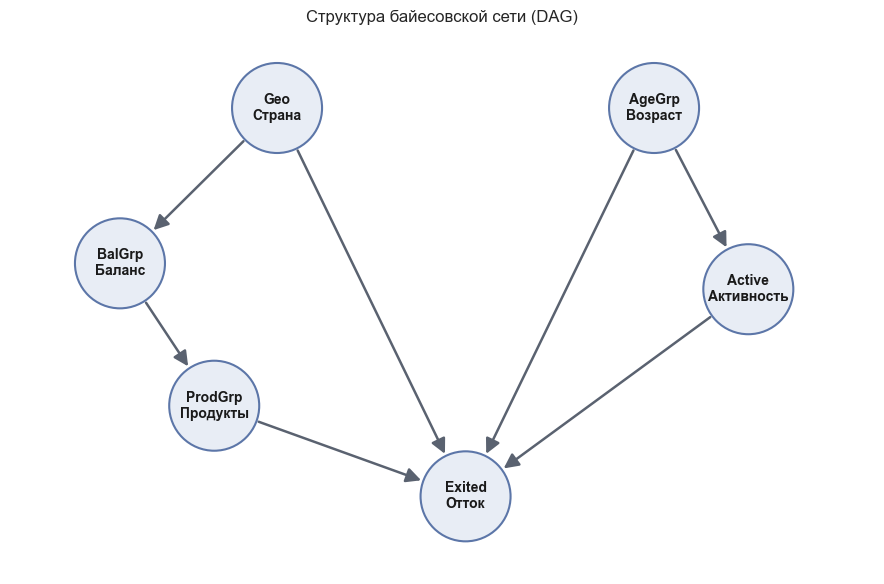

,Пара узлов,Наблюдения,Есть активный путь
0,Geo и AgeGrp,Нет,False
1,Geo и AgeGrp,Exited,True
2,ProdGrp и Active,Нет,False
3,ProdGrp и Active,Exited,True
4,Geo и ProdGrp,Нет,True
5,Geo и ProdGrp,BalGrp,False
6,BalGrp и Exited,"Geo, ProdGrp",False


In [ ]:
import warnings
from itertools import product
import networkx as nx
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.parameter_estimator import DiscreteBayesianEstimator, DiscreteMLE
from pgmpy.inference import VariableElimination

EDGES = [
    ("Geo", "BalGrp"),
    ("Geo", "Exited"),
    ("BalGrp", "ProdGrp"),
    ("AgeGrp", "Active"),
    ("AgeGrp", "Exited"),
    ("ProdGrp", "Exited"),
    ("Active", "Exited"),
]

LABELS = {
    "Geo": "Geo\nСтрана",
    "AgeGrp": "AgeGrp\nВозраст",
    "BalGrp": "BalGrp\nБаланс",
    "ProdGrp": "ProdGrp\nПродукты",
    "Active": "Active\nАктивность",
    "Exited": "Exited\nОтток",
}

POSITIONS = {
    "Geo": (-1.2, 1.5),
    "AgeGrp": (1.2, 1.5),
    "BalGrp": (-2.2, 0.3),
    "ProdGrp": (-1.6, -0.8),
    "Active": (1.8, 0.1),
    "Exited": (0.0, -1.5),
}

def draw_bn(model, observed=(), title="Структура байесовской сети (DAG)"):
    observed = set(observed)
    fig, ax = plt.subplots(figsize=(9, 6))
    node_colors = ["#2855A6" if n in observed else "#E8EDF5" for n in model.nodes()]
    nx.draw_networkx_nodes(
        model, POSITIONS, ax=ax, node_size=4200,
        node_color=node_colors, edgecolors="#5C76A8", linewidths=1.5,
    )
    nx.draw_networkx_edges(
        model, POSITIONS, ax=ax, arrows=True, arrowsize=22,
        width=1.8, edge_color="#5A6270",
        min_source_margin=34, min_target_margin=34,
    )
    for node, (x, y) in POSITIONS.items():
        if node in model:
            ax.text(
                x, y, LABELS[node], ha="center", va="center", fontsize=10,
                fontweight="bold",
                color="white" if node in observed else "#1A1A1A",
            )
    ax.set(title=title, xlim=(-2.9, 2.6), ylim=(-2.1, 2.1))
    ax.axis("off")
    plt.tight_layout()
    plt.show()

dag = DiscreteBayesianNetwork(EDGES)
dag.add_nodes_from(NODES)
assert nx.is_directed_acyclic_graph(dag), "Граф содержит цикл!"
print("Граф является DAG:", nx.is_directed_acyclic_graph(dag))
print("Марковское одеяло Exited:", sorted(dag.get_markov_blanket("Exited")))
print("Марковское одеяло BalGrp:", sorted(dag.get_markov_blanket("BalGrp")))

draw_bn(dag)

dsep_checks = pd.DataFrame([
    {"Пара узлов": "Geo и AgeGrp", "Наблюдения": "Нет",
     "Есть активный путь": dag.is_dconnected("Geo", "AgeGrp")},
    {"Пара узлов": "Geo и AgeGrp", "Наблюдения": "Exited",
     "Есть активный путь": dag.is_dconnected("Geo", "AgeGrp", observed=["Exited"])},
    {"Пара узлов": "ProdGrp и Active", "Наблюдения": "Нет",
     "Есть активный путь": dag.is_dconnected("ProdGrp", "Active")},
    {"Пара узлов": "ProdGrp и Active", "Наблюдения": "Exited",
     "Есть активный путь": dag.is_dconnected("ProdGrp", "Active", observed=["Exited"])},
    {"Пара узлов": "Geo и ProdGrp", "Наблюдения": "Нет",
     "Есть активный путь": dag.is_dconnected("Geo", "ProdGrp")},
    {"Пара узлов": "Geo и ProdGrp", "Наблюдения": "BalGrp",
     "Есть активный путь": dag.is_dconnected("Geo", "ProdGrp", observed=["BalGrp"])},
    {"Пара узлов": "BalGrp и Exited", "Наблюдения": "Geo, ProdGrp",
     "Есть активный путь": dag.is_dconnected("BalGrp", "Exited", observed=["Geo", "ProdGrp"])},
])
display(dsep_checks)

In [12]:
ESS_DEFAULT = 10

def fit_bn(data, edges, method="bdeu", ess=ESS_DEFAULT):
    model = DiscreteBayesianNetwork(edges)
    model.add_nodes_from(NODES)
    if method == "mle":
        est = DiscreteMLE(state_names=STATE_NAMES, n_jobs=1)
    elif method == "bdeu":
        est = DiscreteBayesianEstimator(
            state_names=STATE_NAMES, prior_type="BDeu",
            equivalent_sample_size=ess, n_jobs=1,
        )
    else:
        raise ValueError(f"Неизвестный метод: {method}")
    model.fit(data, estimator=est)
    assert model.check_model(), "Ошибка согласованности модели!"
    return model

def cpd_frame(model, node):
    cpd = model.get_cpds(node)
    parents = cpd.variables[1:]
    parent_states = [cpd.state_names[p] for p in parents]
    rows = []
    for comb in product(*parent_states):
        cond = dict(zip(parents, comb))
        row = cond.copy()
        for st in cpd.state_names[node]:
            row[f"P({node}={st})"] = float(cpd.get_value(**{node: st, **cond}))
        rows.append(row)
    return pd.DataFrame(rows)

mle_model = fit_bn(train_df, EDGES, method="mle")
bn_model = fit_bn(train_df, EDGES, method="bdeu", ess=ESS_DEFAULT)

bn_free_params = sum(
    (len(STATE_NAMES[n]) - 1) * int(np.prod([len(STATE_NAMES[p]) for p in bn_model.get_parents(n)]))
    for n in NODES
)
full_free_params = int(np.prod([len(STATE_NAMES[n]) for n in NODES])) - 1
print(f"Свободных параметров в байесовской сети: {bn_free_params} (в полном совместном распределении: {full_free_params})")

for node in ["Geo", "AgeGrp", "BalGrp", "ProdGrp", "Active"]:
    print(f"\n=== CPT узла {node} (BDeu, ESS={ESS_DEFAULT}) ===")
    display(cpd_frame(bn_model, node).round(4))

Свободных параметров в байесовской сети: 73 (в полном совместном распределении: 323)

=== CPT узла Geo (BDeu, ESS=10) ===


,P(Geo=France),P(Geo=Germany),P(Geo=Spain)
0,0.4989,0.2507,0.2504



=== CPT узла AgeGrp (BDeu, ESS=10) ===


,P(AgeGrp=Young),P(AgeGrp=Mid),P(AgeGrp=Old)
0,0.3668,0.4923,0.1409



=== CPT узла BalGrp (BDeu, ESS=10) ===


,Geo,P(BalGrp=Zero),P(BalGrp=Mid),P(BalGrp=High)
0,France,0.4832,0.2580,0.2588
1,Germany,0.0006,0.5050,0.4945
2,Spain,0.4798,0.2619,0.2584



=== CPT узла ProdGrp (BDeu, ESS=10) ===


,BalGrp,P(ProdGrp=1),P(ProdGrp=2),P(ProdGrp=3+)
0,Zero,0.2502,0.7180,0.0318
1,Mid,0.6502,0.3171,0.0327
2,High,0.6597,0.3073,0.0330



=== CPT узла Active (BDeu, ESS=10) ===


,AgeGrp,P(Active=0),P(Active=1)
0,Young,0.4896,0.5104
1,Mid,0.5188,0.4812
2,Old,0.3560,0.6440


In [13]:
bal_cmp = cpd_frame(mle_model, "BalGrp")[["Geo", "P(BalGrp=Zero)"]].rename(
    columns={"P(BalGrp=Zero)": "MLE: P(Zero)"}
)
bal_cmp["BDeu: P(Zero)"] = cpd_frame(bn_model, "BalGrp")["P(BalGrp=Zero)"].to_numpy()
print("Сравнение MLE vs BDeu для структурного нуля BalGrp=Zero при Geo=Germany:")
display(bal_cmp.round(5))

exited_mle = cpd_frame(mle_model, "Exited").rename(columns={"P(Exited=1)": "MLE"})
exited_bdeu = cpd_frame(bn_model, "Exited").rename(columns={"P(Exited=1)": "BDeu"})

exited_cmp = exited_mle[["Geo", "AgeGrp", "ProdGrp", "Active", "MLE"]].merge(
    exited_bdeu[["Geo", "AgeGrp", "ProdGrp", "Active", "BDeu"]],
    on=["Geo", "AgeGrp", "ProdGrp", "Active"],
).merge(
    exited_support.reset_index()[["Geo", "AgeGrp", "ProdGrp", "Active", "n"]],
    on=["Geo", "AgeGrp", "ProdGrp", "Active"],
)

print("\nРедкие комбинации родителей Exited (n < 10) — влияние сглаживания BDeu:")
display(exited_cmp[exited_cmp["n"] < 10].sort_values("n").round(4))

print("\nПример контраста в хорошо наполненных группах (Geo=Germany, n >= 20):")
display(
    exited_cmp[(exited_cmp["Geo"] == "Germany") & (exited_cmp["n"] >= 20)]
    .sort_values("BDeu", ascending=False)
    .round(4)
)

Сравнение MLE vs BDeu для структурного нуля BalGrp=Zero при Geo=Germany:


,Geo,MLE: P(Zero),BDeu: P(Zero)
0,France,0.48335,0.48322
1,Germany,0.00000,0.00055
2,Spain,0.48002,0.47978



Редкие комбинации родителей Exited (n < 10) — влияние сглаживания BDeu:


,Geo,AgeGrp,ProdGrp,Active,MLE,BDeu,n
53,Spain,Old,3+,1,1.0000,0.9576,2
35,Spain,Young,3+,1,0.3333,0.3383,6
5,Germany,Young,3+,0,0.8750,0.8665,8
8,Spain,Young,3+,0,0.7500,0.7443,8
32,Germany,Young,3+,1,0.6250,0.6222,8
29,France,Young,3+,1,0.5000,0.5000,8
50,Germany,Old,3+,1,1.0000,0.9887,8



Пример контраста в хорошо наполненных группах (Geo=Germany, n >= 20):


,Geo,AgeGrp,ProdGrp,Active,MLE,BDeu,n
41,Germany,Mid,3+,1,0.9600,0.9566,25
14,Germany,Mid,3+,0,0.9355,0.9329,31
21,Germany,Old,1,0,0.8785,0.8779,107
22,Germany,Old,2,0,0.6071,0.6064,28
12,Germany,Mid,1,0,0.5287,0.5286,314
48,Germany,Old,1,1,0.5000,0.5000,112
39,Germany,Mid,1,1,0.3846,0.3847,221
3,Germany,Young,1,0,0.2744,0.2746,164
49,Germany,Old,2,1,0.1967,0.1976,61
13,Germany,Mid,2,0,0.1865,0.1868,193


### Интерпретация полученных CPT

- **Компактность модели:** факторизация по графу сократила число свободных параметров с 323 (полная таблица для $3 \times 3 \times 3 \times 3 \times 2 \times 2$ состояний) до 73.
- **`BalGrp | Geo`:** распределения во Франции и Испании почти идентичны (~48% с нулевым балансом, по ~26% в `Mid` и `High`), тогда как в Германии нулевых балансов на `train` нет вовсе (`MLE = 0.00000`, сглажено `BDeu` до `0.00055`).
- **`ProdGrp | BalGrp`:** у клиентов с нулевым балансом доминируют 2 продукта (71,8%), тогда как при ненулевом балансе (`Mid` и `High`) — наоборот, 1 продукт (~65–66%). При этом строки `Mid` и `High` практически совпадают: ключевое различие проходит именно по границе «нулевой vs ненулевой баланс».
- **Необычный результат в `Active | AgeGrp`:** клиенты старшей группы `Old` заметно *чаще* являются активными (64,4% против 51,0% у `Young` и 48,1% у `Mid`), хотя в целом по выборке именно группа `Old` имеет максимальный отток (45,5%). Возможное объяснение — специфика пользования счётом в старшем возрасте (регулярные зачисления/депозиты) либо «ошибка выжившего»: неактивные возрастные клиенты могли закрыть счета раньше момента среза данных.
- **Контраст и аномалии в `Exited`:** в хорошо наполненных группах Германии вероятность оттока меняется от 3,0% (`Young`, `2` продукта, активен) до 87,8% (`Old`, `1` продукт, неактивен) и 95,7% (`Mid`, `3+` продукта, активен). Примечательно, что при `ProdGrp = 3+` в группе `Germany / Mid` даже активные клиенты уходят почти поголовно (95,7% против 93,3% у неактивных) — фактор 3+ продуктов «перевешивает» активность.
- **Эффект сглаживания (`MLE` vs `BDeu`):** в редких ячейках (`n < 10`, например `Spain / Old / 3+ / Active=1` с `n = 2`) `MLE` выдаёт категоричную `1.0000` (а для Германии с нулевым балансом — строгий `0.0000`), тогда как `BDeu` (`ESS = 10`) аккуратно сглаживает экстремальные оценки (`0.9576` и `0.00055`), почти не искажая наполненные группы (`n >= 20`).

## 5. Вероятностный вывод

Выполним точный вероятностный вывод с помощью алгоритма `VariableElimination` на обученной сети (`BDeu, ESS=10`) и ответим на четыре вопроса, сформулированных до построения графа. Для каждого запроса сравним априорную вероятность события с апостериорной после учёта наблюдений (evidence).

In [14]:
infer = VariableElimination(bn_model)

def query_prob(inference, target, state, evidence=None):
    res = inference.query(
        variables=[target],
        evidence={} if evidence is None else dict(evidence),
        show_progress=False,
    )
    return float(res.get_value(**{target: state}))

query_specs = [
    ("1. Прогнозный запрос", "Exited", 1, {"Geo": "Germany", "AgeGrp": "Old"}),
    ("2. Диагностический вывод", "Active", 0, {"Exited": 1}),
    ("3. Explaining away (Active=0 при ProdGrp=3+)", "Active", 0, {"Exited": 1, "ProdGrp": "3+"}),
]

q_rows = []
for name, target, state, ev in query_specs:
    prior = query_prob(infer, target, state)
    post = query_prob(infer, target, state, ev)
    q_rows.append({
        "Вопрос": name,
        "Событие": f"{target}={state}",
        "Evidence": str(ev),
        "До наблюдений": prior,
        "После наблюдений": post,
        "Изменение, п.п.": 100 * (post - prior),
    })

display(pd.DataFrame(q_rows).round(4))

prod_prior = infer.query(["ProdGrp"], show_progress=False)
prod_germany = infer.query(["ProdGrp"], evidence={"Geo": "Germany"}, show_progress=False)
prod_france = infer.query(["ProdGrp"], evidence={"Geo": "France"}, show_progress=False)

q4_df = pd.DataFrame({
    "ProdGrp": STATE_NAMES["ProdGrp"],
    "P(ProdGrp) априор.": [float(prod_prior.get_value(ProdGrp=s)) for s in STATE_NAMES["ProdGrp"]],
    "P(ProdGrp | Geo=Germany)": [float(prod_germany.get_value(ProdGrp=s)) for s in STATE_NAMES["ProdGrp"]],
    "P(ProdGrp | Geo=France)": [float(prod_france.get_value(ProdGrp=s)) for s in STATE_NAMES["ProdGrp"]],
})
print("\nВопрос 4 — влияние страны на распределение числа продуктов при неизвестном балансе:")
display(q4_df.round(4))

p_mid = query_prob(infer, "ProdGrp", "1", {"BalGrp": "Mid"})
p_mid_ger = query_prob(infer, "ProdGrp", "1", {"BalGrp": "Mid", "Geo": "Germany"})
print(f"Проверка d-разделения (цепь): P(ProdGrp=1 | BalGrp=Mid) = {p_mid:.6f}, "
      f"P(ProdGrp=1 | BalGrp=Mid, Geo=Germany) = {p_mid_ger:.6f}")

ea_df = pd.DataFrame([
    {"Evidence": "Нет наблюдений", "P(Active=0 | e)": query_prob(infer, "Active", 0)},
    {"Evidence": "Exited=1", "P(Active=0 | e)": query_prob(infer, "Active", 0, {"Exited": 1})},
    {"Evidence": "Exited=1, ProdGrp=2", "P(Active=0 | e)": query_prob(infer, "Active", 0, {"Exited": 1, "ProdGrp": "2"})},
    {"Evidence": "Exited=1, ProdGrp=3+", "P(Active=0 | e)": query_prob(infer, "Active", 0, {"Exited": 1, "ProdGrp": "3+"})},
])
print("\nПроверка эффекта explaining away через коллайдер Exited (ProdGrp -> Exited <- Active):")
display(ea_df.round(4))

,Вопрос,Событие,Evidence,До наблюдений,После наблюдений,"Изменение, п.п."
0,1. Прогнозный запрос,Exited=1,"{'Geo': 'Germany', 'AgeGrp': 'Old'}",0.2047,0.5552,35.0527
1,2. Диагностический вывод,Active=0,{'Exited': 1},0.4851,0.6195,13.4362
2,3. Explaining away (Active=0 при ProdGrp=3+),Active=0,"{'Exited': 1, 'ProdGrp': '3+'}",0.4851,0.5197,3.4535



Вопрос 4 — влияние страны на распределение числа продуктов при неизвестном балансе:


,ProdGrp,P(ProdGrp) априор.,P(ProdGrp | Geo=Germany),P(ProdGrp | Geo=France)
0,1,0.5087,0.6546,0.4593
1,2,0.4588,0.3125,0.5083
2,3+,0.0325,0.0329,0.0324


Проверка d-разделения (цепь): P(ProdGrp=1 | BalGrp=Mid) = 0.650153, P(ProdGrp=1 | BalGrp=Mid, Geo=Germany) = 0.650153

Проверка эффекта explaining away через коллайдер Exited (ProdGrp -> Exited <- Active):


,Evidence,P(Active=0 | e)
0,Нет наблюдений,0.4851
1,Exited=1,0.6195
2,"Exited=1, ProdGrp=2",0.6656
3,"Exited=1, ProdGrp=3+",0.5197


### Интерпретация вероятностного вывода

1. **Прогнозный запрос:** знание `Geo=Germany` и `AgeGrp=Old` поднимает оценку риска оттока с априорных **20,47%** до **55,52%** (+35,05 п.п.).
2. **Диагностический вывод:** если известно, что клиент ушёл (`Exited=1`), вероятность его неактивности `Active=0` растёт с базовых **48,51%** до **61,95%** (+13,44 п.п.) — модель передаёт информацию «против стрелки» от следствия к вероятной причине.
3. **Эффект *explaining away* (коллайдер `ProdGrp -> Exited <- Active`):** изначально `ProdGrp` и `Active` независимы, но наблюдение `Exited=1` открывает путь между ними. Если дополнительно узнать, что у ушедшего клиента было `3+` продукта (сильная альтернативная причина оттока), вероятность его неактивности снижается с **61,95%** до **51,97%** (−9,98 п.п.). Напротив, если у ушедшего клиента было `2` продукта (наиболее «надёжная» категория), то для объяснения ухода роль неактивности усиливается, и $P(\text{Active}=0)$ возрастает до **66,56%**.
4. **Косвенный вывод по цепи (`Geo -> BalGrp -> ProdGrp`):** при неизвестном балансе информация `Geo=Germany` меняет прогноз по числу продуктов: вероятность `ProdGrp=1` растёт с **50,87%** до **65,46%**, а `ProdGrp=2` падает с **45,88%** до **31,25%** (так как в Германии почти нет нулевых балансов, а при ненулевом балансе преобладает 1 продукт). Как только фиксируется промежуточный узел `BalGrp=Mid`, цепь блокируется: $P(\text{ProdGrp}=1 \mid \text{BalGrp}=\text{Mid}) = P(\text{ProdGrp}=1 \mid \text{BalGrp}=\text{Mid}, \text{Geo}=\text{Germany}) = 0{,}650153$.

## 6. Эксперимент с последовательным добавлением evidence

Исследуем, как меняется вероятность целевого события $P(\text{Exited}=1 \mid e)$ при пошаговом добавлении информации о клиенте. Специально подберём последовательность так, чтобы проследить:
1. рост риска оттока при неблагоприятных факторах (`Geo=Germany`, `AgeGrp=Old`);
2. снижение риска при появлении «защитных» признаков (`Active=1`, `ProdGrp=2`);
3. отсутствие реакции модели на `BalGrp=High`, когда марковское одеяло узла `Exited` уже зафиксировано (`Geo`, `AgeGrp`, `Active`, `ProdGrp`).

,Шаг,Evidence,P(Exited=1 | evidence)
0,Нет наблюдений,{},0.2047
1,Geo=Germany,{'Geo': 'Germany'},0.3285
2,+ AgeGrp=Old,"{'Geo': 'Germany', 'AgeGrp': 'Old'}",0.5552
3,+ Active=1,"{'Geo': 'Germany', 'AgeGrp': 'Old', 'Active': 1}",0.4216
4,+ ProdGrp=2,"{'Geo': 'Germany', 'AgeGrp': 'Old', 'Active': ...",0.1976
5,+ BalGrp=High (d-разделён),"{'Geo': 'Germany', 'AgeGrp': 'Old', 'Active': ...",0.1976


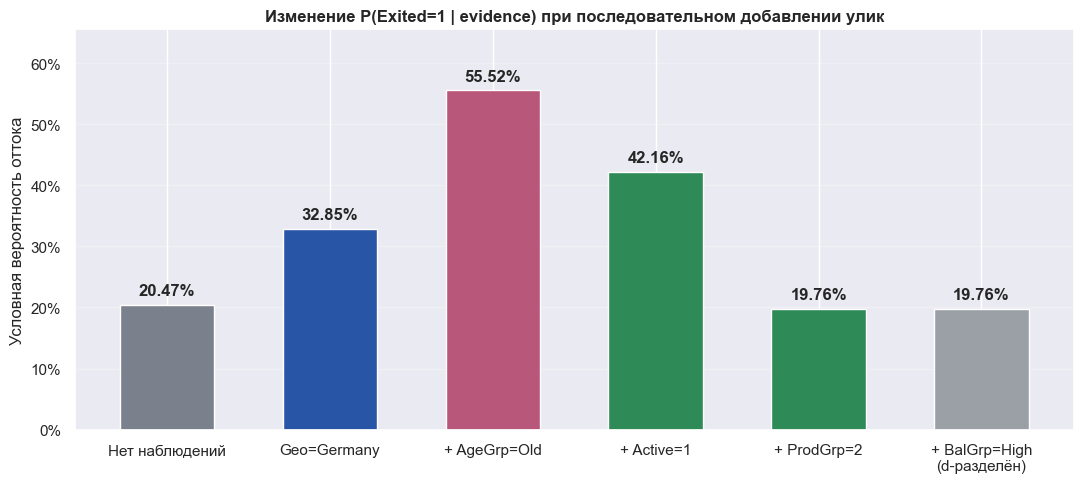

In [ ]:
evidence_steps = [
    ("Нет наблюдений", {}),
    ("Geo=Germany", {"Geo": "Germany"}),
    ("+ AgeGrp=Old", {"Geo": "Germany", "AgeGrp": "Old"}),
    ("+ Active=1", {"Geo": "Germany", "AgeGrp": "Old", "Active": 1}),
    ("+ ProdGrp=2", {"Geo": "Germany", "AgeGrp": "Old", "Active": 1, "ProdGrp": "2"}),
    ("+ BalGrp=High\n(d-разделён)", {"Geo": "Germany", "AgeGrp": "Old", "Active": 1, "ProdGrp": "2", "BalGrp": "High"}),
]

step_rows = []
for label, ev in evidence_steps:
    step_rows.append({
        "Шаг": label.replace("\n", " "),
        "Evidence": str(ev),
        "P(Exited=1 | evidence)": query_prob(infer, "Exited", 1, ev),
    })
ev_df = pd.DataFrame(step_rows)
display(ev_df.round(4))

fig, ax = plt.subplots(figsize=(11, 5))
vals = ev_df["P(Exited=1 | evidence)"].to_numpy()
labels = [s[0] for s in evidence_steps]
bar_colors = ["#7B818C", "#2855A6", "#B9577A", "#2E8B57", "#2E8B57", "#9AA0A6"]

bars = ax.bar(labels, vals, color=bar_colors, width=0.58)
ax.bar_label(bars, labels=[f"{v:.2%}" for v in vals], padding=5, fontweight="bold")
ax.set_title("Изменение P(Exited=1 | evidence) при последовательном добавлении улик", fontweight="bold")
ax.set_ylabel("Условная вероятность оттока")
ax.set_ylim(0, max(vals) * 1.18)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

### Разбор графика последовательного добавления evidence

- Наблюдения меняют вероятность **немонотонно**: базовый риск оттока **20,47%** растёт до **32,85%** при `Geo=Germany` и достигает **55,52%** при добавлении `AgeGrp=Old`.
- Появление «защитных» факторов разворачивает оценку вниз: статус активного клиента (`Active=1`) снижает риск до **42,16%**, а наличие двух продуктов (`ProdGrp=2`) — до **19,76%** (ниже среднего по банку).
- На последнем шаге добавление `BalGrp=High` не меняет результат (**19,76%** $\to$ **19,76%**): к этому моменту уже зафиксированы все узлы марковского одеяла `Exited` (`Geo`, `AgeGrp`, `Active`, `ProdGrp`), поэтому узел `BalGrp` d-разделён с `Exited` и не несёт новой информации.